In [110]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
plt.style.use('_mpl-gallery-nogrid')
def run_df(data):
  try:
    df = pd.read_csv(data, engine='python', on_bad_lines='skip')
    print(f"Format initial du dataset : {df.shape}")

    df = df.dropna(how='all')
    for col in df.columns:
      if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
          mean_value = df[col].mean()
          df[col] = df[col].fillna(mean_value)
        else:
          mode_series = df[col].mode()
          if not mode_series.empty:
            df[col] = df[col].fillna(mode_series[0])

    return df # Retourne le dataframe entier pour l'analyse
  except Exception as e:
    print(f"Could not parse as CSV due to: {e}\n")
    print("Let's inspect the first 500 characters of the file to see its structure:")
    with open(data, 'r', encoding='utf-8', errors='ignore') as f:
      print(f.read(500))

# Exécuté pour initialiser
_ = run_df('education_expenditure_supplementary_data.csv')

Format initial du dataset : (333, 9)


In [111]:
print(plt.style.available)

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


In [112]:
df = run_df('education_expenditure_supplementary_data.csv')

def unique(dataframe):
  for col in dataframe.columns:
    if pd.api.types.is_object_dtype(dataframe[col]):
      print(f"{col} : {dataframe[col].nunique()}\n")

unique(df)

Format initial du dataset : (333, 9)
country : 37

institute_type : 3

direct_expenditure_type : 3



Voici les colonnes sélectionnées : ['1995', '2000', '2005', '2009', '2010', '2011']


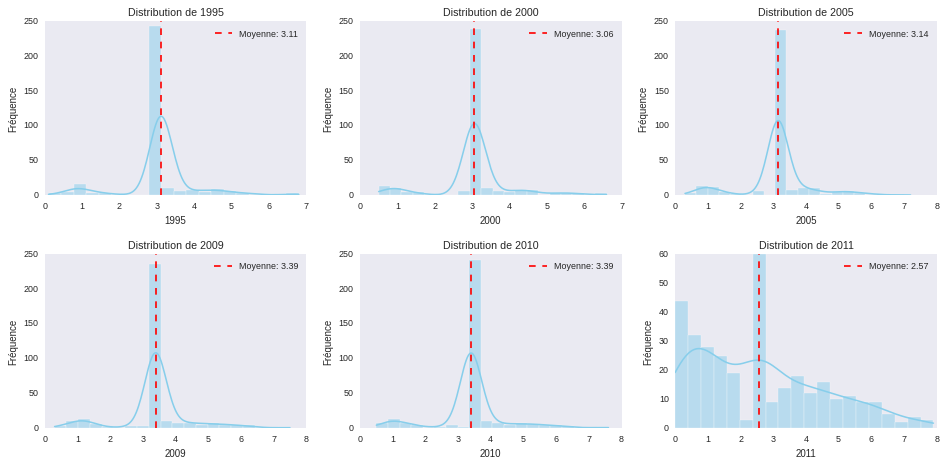

In [113]:
def histogramme(df: pd.DataFrame, line_col: int = 3):
  num_cols = df.select_dtypes(include=[np.number]).columns.to_list()
  if not num_cols:
    print("Aucune colonne numérique n'a été trouvée.")
    return
  print("Voici les colonnes sélectionnées :", num_cols)

  nb_cols = len(num_cols)
  nb_line = (nb_cols + line_col - 1) // line_col

  fig, axs = plt.subplots(nb_line, line_col, figsize=(4 * line_col, 3 * nb_line))

  if nb_cols == 1:
    axs = np.array([axs])
  else:
    axs = axs.flatten()

  for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axs[i], color="skyblue", bins=20)
    # Ajout d'une ligne rouge pointillée pour indiquer la moyenne de chaque colonne
    axs[i].axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Moyenne: {df[col].mean():.2f}")
    axs[i].set_title(f"Distribution de {col}")
    axs[i].set_xlabel(col)
    axs[i].set_ylabel("Fréquence")
    axs[i].legend()

  # Masquer les graphiques excédentaires vides
  for j in range(i + 1, len(axs)):
    fig.delaxes(axs[j])

  plt.tight_layout()
  plt.show()

histogramme(df)

In [114]:
def compte(
    df: pd.DataFrame, colonnes_par_ligne: int = 2
):

  # 1. Sélectionner les colonnes non-numériques (object, category, bool)
  cols_categoriques = df.select_dtypes(
      include=["object", "category", "bool"]
  ).columns.tolist()

  if not cols_categoriques:
    print("❌ Aucune colonne catégorielle trouvée dans le DataFrame.")
    return

  print(f"🏷️ Colonnes catégorielles détectées : {cols_categoriques}")

  nb_cols = len(cols_categoriques)
  nb_lignes = (nb_cols + colonnes_par_ligne - 1) // colonnes_par_ligne

  fig, axes = plt.subplots(
      nrows=nb_lignes,
      ncols=colonnes_par_ligne,
      figsize=(5 * colonnes_par_ligne, 3 * nb_lignes),
  )
  if nb_cols == 1:
    axes = np.array([axes])
  axes = axes.flatten()

  for i, col in enumerate(cols_categoriques):
    sns.countplot(
        data=df,
        y=col,
        ax=axes[i],
        palette="viridis",
        order=df[col].value_counts().index,
    )

    axes[i].set_title(f"Répartition des catégories : {col}")
    axes[i].set_xlabel("Nombre d'occurrences")
    axes[i].set_ylabel(col)


  for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

  plt.tight_layout()
  plt.show()

(df)

,country,institute_type,direct_expenditure_type,1995,2000,2005,2009,2010,2011
0,OECD Average,All Institutions,Public,4.900000,4.900000,5.000000,5.40000,5.400000,5.30000
1,Australia,All Institutions,Public,4.500000,4.600000,4.300000,4.50000,4.600000,4.30000
2,Austria,All Institutions,Public,5.300000,5.400000,5.200000,5.70000,5.600000,5.50000
3,Belgium,All Institutions,Public,5.000000,5.100000,5.800000,6.40000,6.400000,6.40000
4,Canada,All Institutions,Public,5.800000,5.200000,4.800000,5.00000,5.200000,2.57305
...,...,...,...,...,...,...,...,...,...
328,Turkey,Higher Education Institutions,Total,3.106383,3.062626,3.142453,3.38835,3.392079,2.57305
329,United Kingdom,Higher Education Institutions,Total,3.106383,3.062626,3.142453,3.38835,3.392079,1.20000
330,United States,Higher Education Institutions,Total,3.106383,3.062626,3.142453,3.38835,3.392079,2.70000
331,Brazil,Higher Education Institutions,Total,3.106383,3.062626,3.142453,3.38835,3.392079,2.57305


In [115]:
df_country = run_df("school_and_country_table.csv")

Format initial du dataset : (818, 2)


In [116]:
shangai_df = run_df("shanghaiData.csv")

Format initial du dataset : (4897, 11)


In [117]:
df_merge = pd.concat([shangai_df, df_country], axis=1)
df_merge.head()

,world_rank,university_name,national_rank,total_score,alumni,award,hici,ns,pub,pcp,year,school_name,country
0,1,Harvard University,1,100.0,100.0,100.0,100.0,100.0,100.0,72.4,2005,Harvard University,United States of America
1,2,University of Cambridge,1,73.6,99.8,93.4,53.3,56.6,70.9,66.9,2005,California Institute of Technology,United States of America
2,3,Stanford University,2,73.4,41.1,72.2,88.5,70.9,72.3,65.0,2005,Massachusetts Institute of Technology,United States of America
3,4,"University of California, Berkeley",3,72.8,71.8,76.0,69.4,73.9,72.2,52.7,2005,Stanford University,United States of America
4,5,Massachusetts Institute of Technology (MIT),4,70.1,74.0,80.6,66.7,65.8,64.3,53.0,2005,Princeton University,United States of America


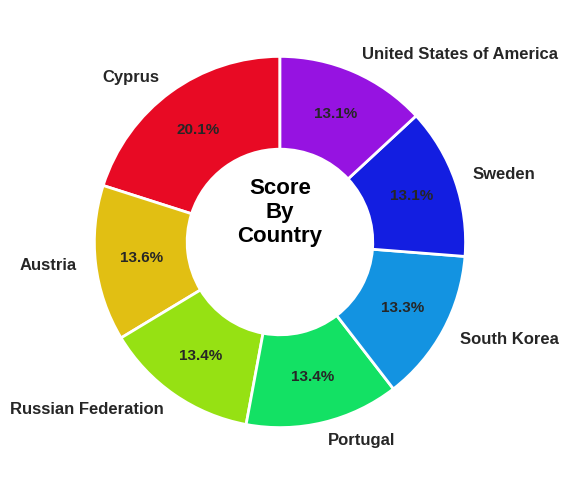

In [144]:
from matplotlib import colors
country = df_merge.groupby('country')['total_score'].mean().sort_values(ascending=False).head(7)
fig,ax = plt.subplots(figsize=(6,5), dpi=100)
colors = ['#e80a24ff', '#e1bf13ff', '#96e113ff', "#13e164ff", "#1393e1ff", "#131ee1ff", "#9613e1ff", "#e113c7ff"]
wedges, texts, autotexts = ax.pie(country.values, labels=country.index, pctdistance=0.75, textprops=dict(fontname='sans-serif'),
                                  wedgeprops=dict(width=0.5, edgecolor='w', linewidth=2), colors=colors, autopct='%1.1f%%', startangle=90)

plt.setp(texts, size=12, weight="bold")
plt.setp(autotexts, size=11, weight="bold")
ax.text(0,0, 'Score\nBy\nCountry', ha='center', fontsize=16, fontweight='bold', color='black')
plt.tight_layout()
plt.show()

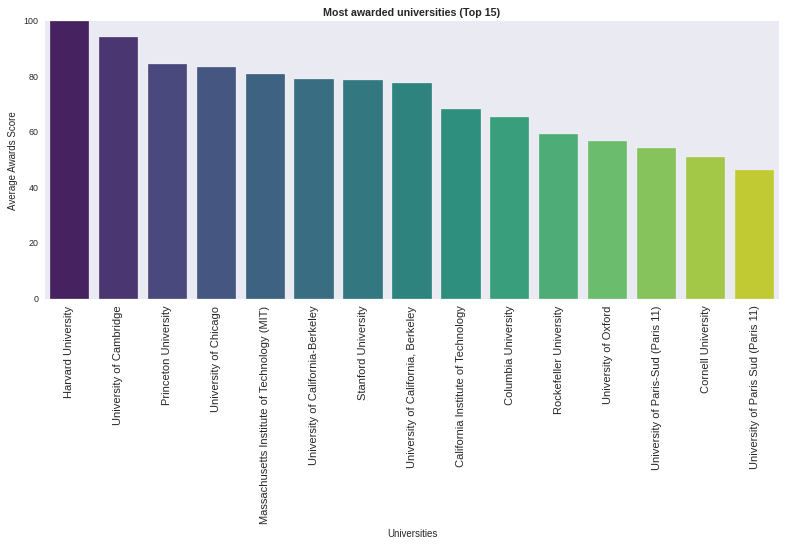

In [129]:
award_df = df_merge.groupby('university_name')['award'].mean().sort_values(ascending=False).head(15).reset_index()

plt.figure(figsize=(10, 7))
ax = sns.barplot(
    data=award_df,
    x='university_name',
    y='award',
    hue='university_name',
    palette='viridis',
    legend=False
)
ax.tick_params(axis='x', labelsize=10)
plt.xticks(rotation=90)
plt.title("Most awarded universities (Top 15)", fontweight='bold')
plt.xlabel("Universities")
plt.ylabel("Average Awards Score")
plt.tight_layout()
plt.show()

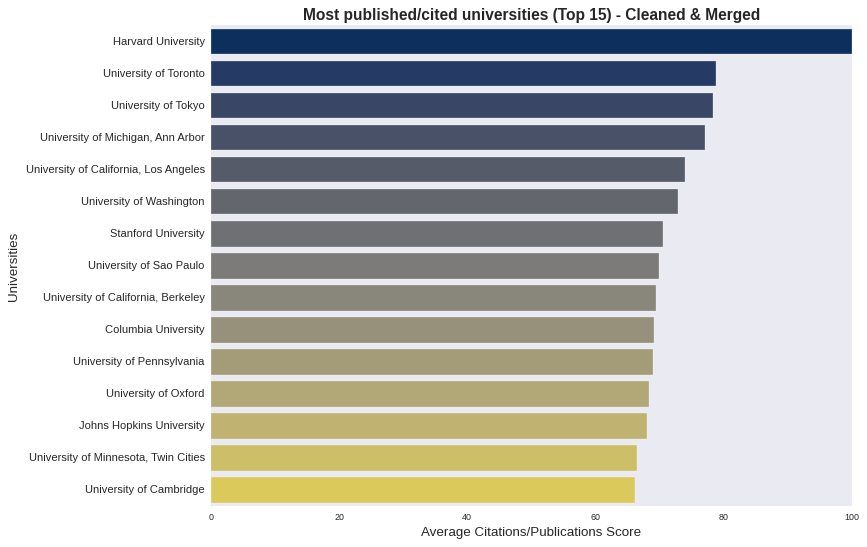

In [139]:
# 1. Nettoyage et standardisation avancée des noms d'universités
df_merge_clean = df_merge.copy()
df_merge_clean['university_name'] = (
    df_merge_clean['university_name']
    .str.replace('-', ', ', regex=False)
    .str.replace(' ,', ',', regex=False)
    .str.replace(r'^The\s+', '', regex=True) # Supprime 'The ' au début du nom
    .str.replace(r'\s+', ' ', regex=True)     # Uniformise les espaces multiples
    .str.strip()
)

# 2. Calculer la moyenne des publications par université (Top 15)
publication = df_merge_clean.groupby('university_name')['pub'].mean().sort_values(ascending=False).head(15).reset_index()

# 3. Générer le graphique horizontal final et épuré
plt.figure(figsize=(11, 7))
ax = sns.barplot(
    data=publication,
    x='pub',
    y='university_name',
    hue='university_name',
    palette='cividis',
    legend=False
)

ax.tick_params(axis='y', labelsize=10)
plt.title("Most published/cited universities (Top 15) - Cleaned & Merged", fontweight='bold', fontsize=14)
plt.xlabel("Average Citations/Publications Score", fontsize=12)
plt.ylabel("Universities", fontsize=12)
plt.tight_layout()
plt.show()

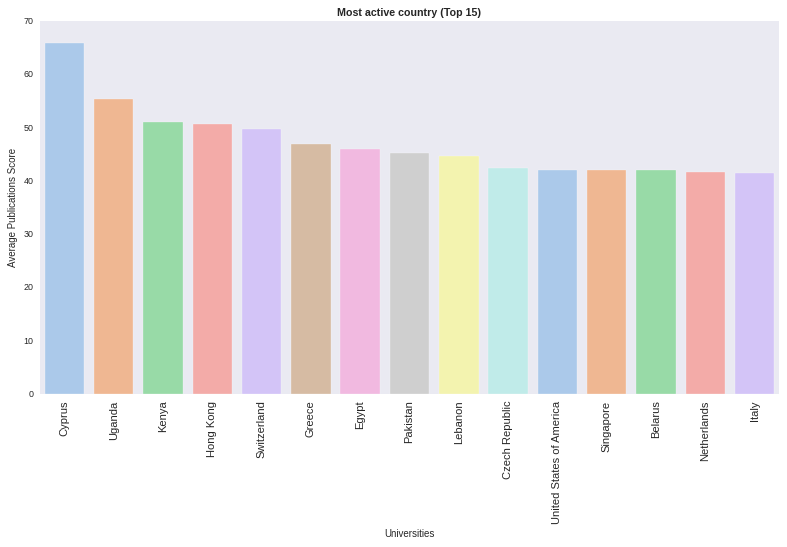

In [141]:
country_pub = df_merge.groupby('country')['pub'].mean().sort_values(ascending=False).head(15).reset_index()
plt.figure(figsize=(10, 7))
ax = sns.barplot(
    data=country_pub,
    x='country',
    y='pub',
    hue='country',
    palette='pastel')
ax.tick_params(axis='x', labelsize=10)
plt.xticks(rotation=90)
plt.title("Most active country (Top 15)", fontweight='bold')
plt.xlabel("Universities")
plt.ylabel("Average Publications Score")
plt.tight_layout()
plt.show()